## Кредитный скоринг: предсказать target (вышел ли клиент в просрочку) по заявке. Метрика - ROC-AUC

In [1]:
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from scipy.stats import rankdata
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

RANDOM_STATE = 42
N_SPLITS, N_REPEATS = 5, 3  # схема кросс-валидации
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

ID_COLS = ["application_id", "client_id", "hash_id"]

### **1. Загружаем данные**

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
transactions = pd.read_csv(DATA_DIR / "transactions.csv")
bureau = pd.read_csv(DATA_DIR / "bureau.csv")
previous_loans = pd.read_csv(DATA_DIR / "previous_loans.csv")

for name, df in [
    ("train", train),
    ("test", test),
    ("transactions", transactions),
    ("bureau", bureau),
    ("previous_loans", previous_loans),
]:
    print(f"{name:16s} {df.shape}")

train            (6488, 25)
test             (2520, 24)
transactions     (353300, 6)
bureau           (24689, 8)
previous_loans   (12762, 7)


In [3]:
train.head()

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,...,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,...,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,...,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,...,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,...,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,...,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0


In [4]:
tx_per_app = transactions.groupby("application_id").size()
tx_dates = pd.to_datetime(transactions["transaction_date"])
span = (
    transactions.assign(d=tx_dates)
    .groupby("application_id")["d"]
    .agg(lambda s: (s.max() - s.min()).days)
)

print(
    "транзакций на заявку:",
    tx_per_app.describe()[["mean", "min", "50%", "max"]].round(1).to_dict(),
)
print(
    "глубина истории, дней:",
    span.describe()[["mean", "min", "50%", "max"]].round(1).to_dict(),
)
print(
    "счетов в бюро на клиента:", round(len(bureau) / bureau["client_id"].nunique(), 1)
)
print(
    "прошлых займов на клиента:",
    round(len(previous_loans) / previous_loans["client_id"].nunique(), 1),
)

транзакций на заявку: {'mean': 39.3, 'min': 19.0, '50%': 39.0, 'max': 76.0}
глубина истории, дней: {'mean': 170.4, 'min': 123.0, '50%': 172.0, 'max': 179.0}
счетов в бюро на клиента: 2.9
прошлых займов на клиента: 1.9


История у всех примерно одинаковой глубины  около 170 дней и ~39 транзакций на заявку.
Это сразу говорит, что окно 180 дней совпадёт с полной историей и будет дублировать
общие агрегаты, поэтомму имеет смысл брать окна  30 и 90 дней.

target
0    0.6578
1    0.3422


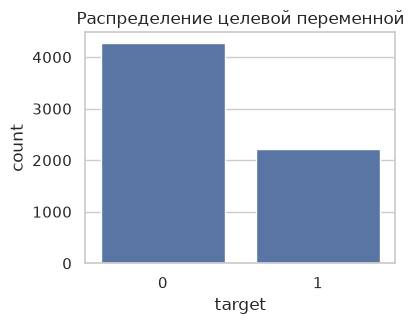

In [5]:
print(train["target"].value_counts(normalize=True).round(4).to_string())

fig, ax = plt.subplots(figsize=(4, 3))
sns.countplot(x="target", data=train, ax=ax)
ax.set_title("Распределение целевой переменной")
plt.show()

Классы умеренно несбалансированны, поэтому спокойно можем использовать ROC-AUC

In [7]:
na_report = pd.DataFrame(
    {
        "train_null_%": train.drop(columns="target").isna().mean() * 100,
        "test_null_%": test.isna().mean() * 100,
    }
).round(2)
na_report["разрыв"] = (na_report["test_null_%"] - na_report["train_null_%"]).round(2)
na_report.sort_values("разрыв", ascending=False)

,train_null_%,test_null_%,разрыв
internal_decision_code,21.18,100.00,78.82
post_loan_collection_score,23.71,100.00,76.29
days_until_first_overdue,28.61,100.00,71.39
hash_id,6.43,9.09,2.66
monthly_income,6.80,9.37,2.57
interest_rate,5.78,8.06,2.28
requested_product,5.89,7.62,1.73
months_at_job,5.95,7.58,1.63
incoming_amount,6.67,8.02,1.35
region_coefficient,5.49,6.71,1.22


В test пропущенны признаки `internal_decision_code`, `post_loan_collection_score` и `days_until_first_overdue`, при этом они есть в train 

In [8]:
def univariate_auc(values, y):
    v = pd.to_numeric(values, errors="coerce").to_numpy(dtype=float)
    mask = np.isfinite(v)
    if mask.sum() < 100 or np.std(v[mask]) == 0:
        return np.nan
    auc = roc_auc_score(y[mask], v[mask])
    return max(auc, 1 - auc)


y_full = train["target"].to_numpy()
suspects = na_report[na_report["test_null_%"] > 99].index.tolist()
for col in suspects:
    print(
        f"  {col:28s} univariate AUC в train = {univariate_auc(train[col], y_full):.4f}"
    )

  days_until_first_overdue     univariate AUC в train = 0.9507
  internal_decision_code       univariate AUC в train = nan
  post_loan_collection_score   univariate AUC в train = 0.9107


`post_loan_collection_score` и `days_until_first_overdue` дают AUC 0.91 и 0.95  это данные,
появляющиеся после выдачи займа, то есть классическая утечка целевой переменной.

`internal_decision_code` пропущен целиком. Все три признака исключаем. Именно на этом ошибался simple_baseline.ipynb

In [9]:
LEAKY_COLS = [
    "post_loan_collection_score",
    "days_until_first_overdue",
    "internal_decision_code",
]

### **3. Числовые признаки**

Считаем univariate AUC для каждого **числового** признака. он прямо отвечает на вопрос "насколько этот признак сам по себе упорядочивает клиентов по риску"

признаки-константы: {'region_coefficient': [1.0]}


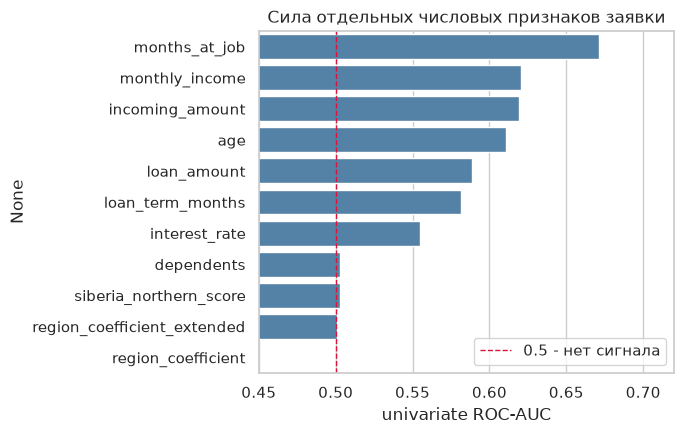

,univariate_auc
months_at_job,0.6714
monthly_income,0.6202
incoming_amount,0.6192
age,0.6108
loan_amount,0.5885
loan_term_months,0.5814
interest_rate,0.5551
dependents,0.5025
siberia_northern_score,0.5025
region_coefficient_extended,0.5006


In [10]:
num_cols = [
    c
    for c in train.columns
    if c not in ID_COLS + LEAKY_COLS + ["target", "application_date"]
    and pd.api.types.is_numeric_dtype(train[c])
]

constants = [c for c in num_cols if train[c].nunique(dropna=True) <= 1]
print(
    "признаки-константы:", {c: train[c].dropna().unique().tolist() for c in constants}
)

uni = (
    pd.Series({c: univariate_auc(train[c], y_full) for c in num_cols})
    .sort_values(ascending=False)
    .round(4)
)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=uni.to_numpy(), y=uni.index, ax=ax, color="steelblue")
ax.axvline(0.5, color="crimson", ls="--", lw=1, label="0.5 - нет сигнала")
ax.set_xlim(0.45, 0.72)
ax.set_xlabel("univariate ROC-AUC")
ax.set_title("Сила отдельных числовых признаков заявки")
ax.legend()
plt.tight_layout()
plt.show()

uni.to_frame("univariate_auc")

Значимые сигналы есть у `months_at_job`, `monthly_income`, `incoming_amount`, `age`, `loan_amount`, `loan_term_months`, `interest_rate`


`region_coefficient` - константа.

Oстальные признаки `dependents`, `siberia_northern_score` и `region_coefficient_extended` шум

In [11]:
NOISE_NUM = [
    "region_coefficient",
    "region_coefficient_extended",
    "siberia_northern_score",
    "dependents",
    # Производные фичи, которые мы построим дальше и который унаследуют шум
    "region_coef_diff",
    "region_x_siberia",
    "income_x_region",
    "income_per_dependent",
    "disposable_per_head",
]

### **3. Категориальные признаки**

Проблема: если закодировать категорию средним таргетом по всей выборке и на ней же померить качество, признак с большим числом категорий всегда будет выглядеть сильным - среднее по категории посчитано по тем же строкам, на которых меряем. Бустинг такой признак с радостью выведет в топ важностей.

Решение: посчитать target encoding двумя способами и сравнить:

Способ 1) in-fold: train.groupby(col)["target"].transform("mean") - по всей выборке

Способ 2) out-of-fold: 5-фолдовый цикл, где среднее по категории считается только по обучающей части, а неизвестные категории заменяются глобальным prior.

In [12]:
cat_cols = [
    c
    for c in train.columns
    if not pd.api.types.is_numeric_dtype(train[c])
    and c not in LEAKY_COLS + ["application_date"]
]

rows = []
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
prior = y_full.mean()

for col in cat_cols:
    # закодировали по всей выборке и на ней же измерили AUC
    in_fold = train.groupby(col)["target"].transform("mean")

    # честное кодирование: среднее считается только по train-части фолда
    oof = np.full(len(train), np.nan)
    for tr_idx, va_idx in skf.split(train, y_full):
        means = train.iloc[tr_idx].groupby(col)["target"].mean()
        oof[va_idx] = train.iloc[va_idx][col].map(means).fillna(prior).to_numpy()

    rows.append(
        {
            "признак": col,
            "категорий": train[col].nunique(),
            "строк на категорию": round(len(train) / train[col].nunique(), 1),
            "AUC in-fold": round(univariate_auc(pd.Series(in_fold), y_full), 4),
            "AUC out-of-fold": round(univariate_auc(pd.Series(oof), y_full), 4),
        }
    )

cat_report = pd.DataFrame(rows).sort_values("AUC out-of-fold", ascending=False)
cat_report

,признак,категорий,строк на категорию,AUC in-fold,AUC out-of-fold
0,employment_type,5,1297.6,0.6013,0.5904
2,requested_product,5,1297.6,0.5591,0.5546
5,region,7,926.9,0.5313,0.5149
1,education,4,1622.0,0.5082,0.5033
3,channel,5,1297.6,0.5119,0.5019
4,marketing_segment,150,43.3,0.5889,0.5019


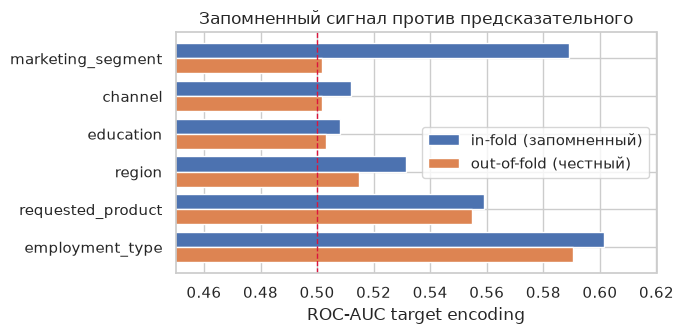

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
idx = np.arange(len(cat_report))
ax.barh(idx + 0.2, cat_report["AUC in-fold"], height=0.4, label="in-fold (запомненный)")
ax.barh(
    idx - 0.2, cat_report["AUC out-of-fold"], height=0.4, label="out-of-fold (честный)"
)
ax.set_yticks(idx, cat_report["признак"])
ax.axvline(0.5, color="crimson", ls="--", lw=1)
ax.set_xlim(0.45, 0.62)
ax.set_xlabel("ROC-AUC target encoding")
ax.set_title("Запомненный сигнал против предсказательного")
ax.legend()
plt.tight_layout()
plt.show()

 `employment_type` - 0.590 out-of-fold при 0.601 in-fold: разрыв минимальный, сигнал
  настоящий. То же у `requested_product` (0.555 против 0.559);
 
 `region` (0.515) - слабый, но не нулевой, оставляем;
 
 `education` (0.503) и `channel` (0.502) - шум;
 
 `marketing_segment`: in-fold 0.589, out-of-fold 0.502. Разрыв 0.087 - на порядок
  больше, чем у любого другого признака. 150 категорий на 6488 строк, около 43 строки на
  категорию: модель их запоминает, а предсказательной силы нет вообще.

Обратим внимание на форму зависимости: разрыв между in-fold и out-of-fold тем больше,
чем мельче категории. Проверим это на самом `marketing_segment`.

In [14]:
seg_sizes = train["marketing_segment"].value_counts()
print(
    f"marketing_segment: {seg_sizes.size} категорий, "
    f"медиана размера {seg_sizes.median():.0f} строк, "
    f"{(seg_sizes < 50).mean():.0%} категорий меньше 50 строк"
)

NOISE_CAT = ["marketing_segment", "channel", "education"]

marketing_segment: 150 категорий, медиана размера 40 строк, 93% категорий меньше 50 строк


`marketing_segment` - самый дорогой признак в этой задаче: в наших замерах его удаление
в одиночку давало около **+0.008 OOF AUC**. Убираем его вместе с `channel` и `education`.

In [15]:
# Делаем дишевые проверки на утечку

# (1) Транзакции должны строго предшествовать заявке.
chk = transactions.merge(
    train[["application_id", "application_date"]], on="application_id"
)
after = (
    pd.to_datetime(chk["transaction_date"]) >= pd.to_datetime(chk["application_date"])
).mean()
print(f"транзакций в день заявки или позже: {after:.2%}")

# (2) Идентификаторы не должны нести сигнала. Если несут - в данных есть порядок,
#     связанный с таргетом, и модель будет учиться на артефакте выгрузки.
for col in ["application_id", "client_id", "hash_id"]:
    print(f"{col:16s} univariate AUC = {univariate_auc(train[col], y_full):.4f}")

# (3) Дата заявки: ни тренда, ни сдвига между train и test быть не должно.
app_dt = pd.to_datetime(train["application_date"])
print(
    f"\napplication_date как число: AUC = {univariate_auc(app_dt.astype('int64'), y_full):.4f}"
)
print(f"пропусков в application_date: {train['application_date'].isna().mean():.1%}")
monthly = (
    train.assign(m=app_dt.dt.to_period("M").astype(str))
    .groupby("m")["target"]
    .agg(["mean", "size"])
)
print(
    f"доля просрочки по месяцам: от {monthly['mean'].min():.3f} до {monthly['mean'].max():.3f}"
)
print("диапазон дат train:", app_dt.min().date(), "-", app_dt.max().date())
print(
    "диапазон дат test: ",
    pd.to_datetime(test["application_date"]).min().date(),
    "-",
    pd.to_datetime(test["application_date"]).max().date(),
)

транзакций в день заявки или позже: 0.00%
application_id   univariate AUC = 0.5125
client_id        univariate AUC = 0.5125
hash_id          univariate AUC = 0.5111

application_date как число: AUC = 0.5039
пропусков в application_date: 7.2%
доля просрочки по месяцам: от 0.317 до 0.364
диапазон дат train: 2025-01-01 - 2025-12-31
диапазон дат test:  2025-01-01 - 2025-12-31


Всё чисто: транзакции строго до заявки (утечки по времени нет), идентификаторы дают AUC
около 0.51, помесячная доля просрочки ровная, train и test покрывают один и тот же год.
Разбиение на train/test случайное, а не по времени - значит, обычная стратифицированная
кросс-валидация корректна, отдельная схема с временным разрезом не нужна.

Отдельно: `application_date` пропущен у 7% заявок. При построении оконных признаков
по транзакциям для таких заявок точкой отсчёта возьмём максимальную дату транзакции + 1 день.

Проверяем, отличимы ли train и test по признакам. Если модель научится их различать,
локальной кросс-валидации доверять нельзя.

In [16]:
adv = pd.concat(
    [train.drop(columns="target").assign(is_test=0), test.assign(is_test=1)],
    ignore_index=True,
    sort=False,
)
adv_feats = [
    c
    for c in adv.columns
    if c not in ID_COLS + LEAKY_COLS + ["is_test", "application_date"]
]
X_adv = adv[adv_feats].copy()
adv_cats = [c for c in adv_feats if not pd.api.types.is_numeric_dtype(X_adv[c])]
for c in adv_cats:
    X_adv[c] = X_adv[c].astype("category")

adv_oof = np.zeros(len(adv))
for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(
    X_adv, adv["is_test"]
):
    m = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        verbosity=-1,
        random_state=RANDOM_STATE,
    )
    m.fit(X_adv.iloc[tr_idx], adv["is_test"].iloc[tr_idx], categorical_feature=adv_cats)
    adv_oof[va_idx] = m.predict_proba(X_adv.iloc[va_idx])[:, 1]

print(f"adversarial ROC-AUC = {roc_auc_score(adv['is_test'], adv_oof):.4f}")

adversarial ROC-AUC = 0.5106


AUC около 0.5 - train и test неотличимы, сдвига распределений нет. Локальной оценке
можно доверять, псевдо-лейблинг и коррекция под сдвиг не нужны.

Главная незакрытая возможность в исходных данных - **время транзакций**. Простые агрегаты
по всей истории (сумма, среднее, доли категорий) теряют динамику: клиент, у которого траты выросли втрое за последний месяц, и клиент с ровным профилем выглядят
одинаково.

Строим четыре блока.

- окна 30 и 90 дней: отток, приток, счёт, gambling, платежи по займам, снятия наличных;
- тренды: последние 90 дней против предыдущих;
- recency по каждой категории - сколько дней назад была последняя такая операция;
- регулярность зарплаты (`salary_gap_std`, `salary_cv`) и **вменённый доход из зарплатных
  транзакций против заявленного** (`salary_vs_declared`) - прямая проверка анкеты;
- прокси остатка на счёте через накопительную сумму: минимум, разброс, доля времени в минусе;
- риск мерчантов, взвешенный по сумме, доля выходных, волатильность дневного нетто.

In [17]:
TX_CATEGORIES = [
    "groceries",
    "transfer",
    "cash_withdrawal",
    "salary",
    "entertainment",
    "loan_payment",
    "utilities",
    "gambling",
]


def build_transaction_features(tx: pd.DataFrame, apps: pd.DataFrame) -> pd.DataFrame:
    """Агрегаты по транзакциям на уровне application_id.

    apps - таблица [application_id, application_date] по train и test сразу: точка отсчёта
    для оконных признаков нужна одна и та же для обеих выборок.
    """
    tx = tx.copy()
    tx["transaction_date"] = pd.to_datetime(tx["transaction_date"])

    ref = apps.copy()
    ref["application_date"] = pd.to_datetime(ref["application_date"])
    # для 7% заявок без даты берём последнюю транзакцию + 1 день
    last_tx = tx.groupby("application_id")["transaction_date"].max()
    ref["ref_date"] = ref["application_date"].fillna(
        ref["application_id"].map(last_tx) + pd.Timedelta(days=1)
    )

    tx = tx.merge(ref[["application_id", "ref_date"]], on="application_id", how="left")
    tx["days_before"] = (tx["ref_date"] - tx["transaction_date"]).dt.days

    tx["is_out"] = tx["amount"] < 0
    tx["absamt"] = tx["amount"].abs()
    tx["out_amt"] = np.where(tx["is_out"], tx["absamt"], 0.0)
    tx["in_amt"] = np.where(~tx["is_out"], tx["absamt"], 0.0)
    tx["is_weekend"] = tx["transaction_date"].dt.dayofweek >= 5
    tx["risk_amt"] = tx["merchant_risk_level"] * tx["out_amt"]
    tx["hi_risk"] = tx["merchant_risk_level"] >= 4

    g = tx.groupby("application_id")
    f = g.agg(
        tx_count=("amount", "size"),
        tx_span_days=("days_before", "max"),
        tx_recency=("days_before", "min"),
        tx_days_before_mean=("days_before", "mean"),
        tx_amount_sum=("amount", "sum"),
        tx_amount_mean=("amount", "mean"),
        tx_amount_std=("amount", "std"),
        tx_absamt_max=("absamt", "max"),
        tx_absamt_median=("absamt", "median"),
        tx_outflow_sum=("out_amt", "sum"),
        tx_inflow_sum=("in_amt", "sum"),
        tx_out_count=("is_out", "sum"),
        merchant_risk_mean=("merchant_risk_level", "mean"),
        merchant_risk_max=("merchant_risk_level", "max"),
        merchant_risk_std=("merchant_risk_level", "std"),
        hi_risk_share=("hi_risk", "mean"),
        risk_amt_sum=("risk_amt", "sum"),
        weekend_share=("is_weekend", "mean"),
        n_active_days=("transaction_date", "nunique"),
    )
    f["net_cashflow"] = f["tx_inflow_sum"] - f["tx_outflow_sum"]
    f["outflow_to_inflow_ratio"] = f["tx_outflow_sum"] / f["tx_inflow_sum"].replace(
        0, np.nan
    )
    f["tx_per_day"] = f["tx_count"] / f["tx_span_days"].replace(0, np.nan)
    f["risk_amt_per_out"] = f["risk_amt_sum"] / f["tx_outflow_sum"].replace(0, np.nan)
    f["tx_out_rate"] = f["tx_out_count"] / f["tx_count"]

    # разрезы по категориям: объём, средний чек и давность последней операции
    for c in TX_CATEGORIES:
        gc = tx[tx["transaction_category"] == c].groupby("application_id")
        f[f"cnt_{c}"] = gc.size()
        f[f"amt_{c}"] = gc["absamt"].sum()
        f[f"mean_{c}"] = gc["absamt"].mean()
        f[f"rec_{c}"] = gc["days_before"].min()
    for c in TX_CATEGORIES:
        f[f"cnt_{c}"] = f[f"cnt_{c}"].fillna(0)
        f[f"amt_{c}"] = f[f"amt_{c}"].fillna(0)
        f[f"share_{c}"] = f[f"cnt_{c}"] / f["tx_count"]
        f[f"amtshare_{c}"] = f[f"amt_{c}"] / f["tx_outflow_sum"].replace(0, np.nan)

    # регулярность зарплаты и вменённый доход
    sal = tx[tx["transaction_category"] == "salary"].sort_values(
        ["application_id", "transaction_date"]
    )
    sg = sal.groupby("application_id")
    f["salary_amt_std"] = sg["absamt"].std()
    f["salary_amt_max"] = sg["absamt"].max()
    f["salary_amt_min"] = sg["absamt"].min()
    f["salary_gap_std"] = sal.groupby("application_id")["days_before"].apply(
        lambda s: s.sort_values().diff().std()
    )
    f["salary_monthly_implied"] = f["amt_salary"] / (
        f["tx_span_days"].replace(0, np.nan) / 30.44
    )
    f["salary_cv"] = f["salary_amt_std"] / f["mean_salary"].replace(0, np.nan)

    # окна: 180 дней совпало бы с полной историей, поэтому только 30 / 90
    for w in (30, 90):
        sub = tx[tx["days_before"] <= w]
        gw = sub.groupby("application_id")
        f[f"out_{w}d"] = gw["out_amt"].sum()
        f[f"in_{w}d"] = gw["in_amt"].sum()
        f[f"cnt_{w}d"] = gw.size()
        for c in ("gambling", "loan_payment", "cash_withdrawal"):
            short = {
                "gambling": "gamb",
                "loan_payment": "loanpay",
                "cash_withdrawal": "cash",
            }[c]
            f[f"{short}_{w}d"] = (
                sub[sub["transaction_category"] == c]
                .groupby("application_id")["absamt"]
                .sum()
            )
        f[f"risk_{w}d"] = gw["merchant_risk_level"].mean()
        for col in [
            f"out_{w}d",
            f"in_{w}d",
            f"cnt_{w}d",
            f"gamb_{w}d",
            f"loanpay_{w}d",
            f"cash_{w}d",
        ]:
            f[col] = f[col].fillna(0)
        f[f"net_{w}d"] = f[f"in_{w}d"] - f[f"out_{w}d"]
        f[f"o2i_{w}d"] = f[f"out_{w}d"] / f[f"in_{w}d"].replace(0, np.nan)

    # тренд: последние 90 дней против всего, что было раньше
    f["out_trend_90"] = f["out_90d"] / (f["tx_outflow_sum"] - f["out_90d"]).replace(
        0, np.nan
    )
    f["in_trend_90"] = f["in_90d"] / (f["tx_inflow_sum"] - f["in_90d"]).replace(
        0, np.nan
    )
    f["gamb_trend"] = f["gamb_90d"] / f["amt_gambling"].replace(0, np.nan)
    f["cnt_trend_30"] = (f["cnt_30d"] / 30) / (
        f["tx_count"] / f["tx_span_days"].replace(0, np.nan)
    ).replace(0, np.nan)

    # прокси остатка на счёте: накопительная сумма движений в хронологии
    txs = tx.sort_values(["application_id", "transaction_date"])
    txs["cum"] = txs.groupby("application_id")["amount"].cumsum()
    cg = txs.groupby("application_id")["cum"]
    f["bal_min"] = cg.min()
    f["bal_max"] = cg.max()
    f["bal_last"] = cg.last()
    f["bal_std"] = cg.std()
    f["bal_neg_share"] = (
        txs.assign(neg=txs["cum"] < 0).groupby("application_id")["neg"].mean()
    )

    # волатильность дневного нетто
    daily = (
        tx.groupby(["application_id", "transaction_date"])["amount"]
        .sum()
        .groupby("application_id")
    )
    f["daily_net_std"] = daily.std()
    f["daily_net_min"] = daily.min()

    return f.reset_index()

Помимо обычных сумм и utilization важны две вещи, которых нет в наивных агрегатах:
счётчики просрочек по порогам (30 и 90 дней - просрочка на 5 дней и на 95 качественно
разные), и **«кредитный голод»** - сколько счетов клиент открыл за последние 180/365 дней.

In [18]:
def build_bureau_features(b: pd.DataFrame) -> pd.DataFrame:
    """Агрегаты внешней кредитной истории на уровне client_id."""
    b = b.copy()
    b["utilization"] = b["current_balance"] / b["credit_limit"].replace(0, np.nan)
    b["is_active"] = b["bureau_status"].eq("active")
    b["has_dpd"] = b["max_dpd_last_12m"] > 0
    b["dpd30"] = b["max_dpd_last_12m"] >= 30
    b["dpd90"] = b["max_dpd_last_12m"] >= 90
    b["avail"] = b["credit_limit"] - b["current_balance"]

    f = b.groupby("client_id").agg(
        bureau_accounts_count=("bureau_account_id", "size"),
        bureau_active_count=("is_active", "sum"),
        bureau_credit_limit_sum=("credit_limit", "sum"),
        bureau_credit_limit_max=("credit_limit", "max"),
        bureau_credit_limit_mean=("credit_limit", "mean"),
        bureau_balance_sum=("current_balance", "sum"),
        bureau_balance_max=("current_balance", "max"),
        bureau_utilization_mean=("utilization", "mean"),
        bureau_utilization_max=("utilization", "max"),
        bureau_utilization_std=("utilization", "std"),
        bureau_max_dpd=("max_dpd_last_12m", "max"),
        bureau_dpd_mean=("max_dpd_last_12m", "mean"),
        bureau_dpd_sum=("max_dpd_last_12m", "sum"),
        bureau_dpd_std=("max_dpd_last_12m", "std"),
        bureau_n_dpd=("has_dpd", "sum"),
        bureau_n_dpd30=("dpd30", "sum"),
        bureau_n_dpd90=("dpd90", "sum"),
        bureau_min_opened_days_ago=("opened_days_ago", "min"),
        bureau_max_opened_days_ago=("opened_days_ago", "max"),
        bureau_mean_opened_days_ago=("opened_days_ago", "mean"),
        bureau_std_opened_days_ago=("opened_days_ago", "std"),
        bureau_avail_sum=("avail", "sum"),
    )
    f["bureau_overall_utilization"] = f["bureau_balance_sum"] / f[
        "bureau_credit_limit_sum"
    ].replace(0, np.nan)
    f["bureau_active_share"] = f["bureau_active_count"] / f["bureau_accounts_count"]
    f["bureau_dpd_share"] = f["bureau_n_dpd"] / f["bureau_accounts_count"]
    f["bureau_history_len"] = f["bureau_max_opened_days_ago"]
    f["bureau_acct_per_year"] = f["bureau_accounts_count"] / (
        f["bureau_max_opened_days_ago"].replace(0, np.nan) / 365.25
    )

    act = b[b["is_active"]].groupby("client_id")
    f["bureau_active_balance"] = act["current_balance"].sum()
    f["bureau_active_limit"] = act["credit_limit"].sum()
    f["bureau_active_dpd_max"] = act["max_dpd_last_12m"].max()
    f["bureau_active_util"] = f["bureau_active_balance"] / f[
        "bureau_active_limit"
    ].replace(0, np.nan)

    # «кредитный голод»: сколько счетов открыто недавно
    for w in (180, 365):
        f[f"bureau_opened_{w}d"] = (
            b[b["opened_days_ago"] <= w].groupby("client_id").size()
        )
        f[f"bureau_opened_{w}d"] = f[f"bureau_opened_{w}d"].fillna(0)

    for t in ["credit_card", "consumer", "microloan", "auto", "mortgage"]:
        sub = b[b["account_type"] == t].groupby("client_id")
        f[f"bt_cnt_{t}"] = sub.size().reindex(f.index).fillna(0)
        f[f"bt_bal_{t}"] = sub["current_balance"].sum()
        f[f"bt_dpd_{t}"] = sub["max_dpd_last_12m"].max()
        f[f"bureau_type_share_{t}"] = f[f"bt_cnt_{t}"] / f["bureau_accounts_count"]

    return f.reset_index()

Ключевая идея - **взвесить просрочки по свежести**: просрочка трёхлетней давности и
просрочка полугодовой давности говорят о риске очень по-разному, а обычный `mean` их
уравнивает.

In [19]:
def build_previous_loans_features(pl: pd.DataFrame) -> pd.DataFrame:
    """Агрегаты прошлых займов на уровне client_id."""
    f = pl.groupby("client_id").agg(
        prev_loans_count=("previous_loan_id", "size"),
        prev_amount_sum=("previous_amount", "sum"),
        prev_amount_mean=("previous_amount", "mean"),
        prev_amount_max=("previous_amount", "max"),
        prev_amount_std=("previous_amount", "std"),
        prev_term_mean=("previous_term_months", "mean"),
        prev_term_max=("previous_term_months", "max"),
        prev_overdue_rate=("was_overdue", "mean"),
        prev_overdue_count=("was_overdue", "sum"),
        prev_max_overdue_days=("max_overdue_days", "max"),
        prev_mean_overdue_days=("max_overdue_days", "mean"),
        prev_sum_overdue_days=("max_overdue_days", "sum"),
        prev_last_closed_days_ago=("closed_days_ago", "min"),
        prev_first_closed_days_ago=("closed_days_ago", "max"),
        prev_closed_days_std=("closed_days_ago", "std"),
    )
    f["prev_tenure"] = f["prev_first_closed_days_ago"] - f["prev_last_closed_days_ago"]
    f["prev_loans_per_year"] = f["prev_loans_count"] / (
        f["prev_first_closed_days_ago"].replace(0, np.nan) / 365.25
    )

    # доля просрочек, взвешенная по свежести: вес 1/(1 + лет назад)
    w = 1.0 / (
        1.0 + pl["closed_days_ago"].fillna(pl["closed_days_ago"].median()) / 365.25
    )
    tmp = pl.assign(_w=w, _num=pl["was_overdue"] * w)
    agg = tmp.groupby("client_id")[["_num", "_w"]].sum()
    f["prev_overdue_rate_recw"] = agg["_num"] / agg["_w"].replace(0, np.nan)

    rec = pl[pl["closed_days_ago"] <= 730].groupby("client_id")
    f["prev_cnt_2y"] = rec.size().reindex(f.index).fillna(0)
    f["prev_overdue_2y"] = rec["was_overdue"].sum().reindex(f.index).fillna(0)
    f["prev_amount_2y"] = rec["previous_amount"].sum()
    return f.reset_index()

Здесь считаем аннуитетный платёж по формуле и строим долговую нагрузку. `PTI`
(payment-to-income) и `total_debt_burden` - стандартные банковские метрики, которых
в сырых данных нет, а сигнал они несут прямой.

Кросс-таблицы связывают анкету с наблюдаемым поведением: заявленный доход против дохода
из зарплатных транзакций, запрошенная сумма против лимитов в бюро и против прошлых займов.

In [20]:
def build_application_features(df: pd.DataFrame) -> pd.DataFrame:
    """Признаки из полей заявки."""
    d = df.copy()
    dt = pd.to_datetime(d["application_date"])
    d["app_month"] = dt.dt.month
    d["app_dayofweek"] = dt.dt.dayofweek

    inc = d["monthly_income"].replace(0, np.nan)
    d["income_to_loan_ratio"] = inc / d["loan_amount"].replace(0, np.nan)
    d["loan_to_income"] = d["loan_amount"] / inc
    d["loan_to_income_x_term"] = d["loan_amount"] / (
        inc * d["loan_term_months"]
    ).replace(0, np.nan)

    # аннуитетный платёж и производные от него метрики нагрузки
    r = d["interest_rate"] / 12.0
    n = d["loan_term_months"]
    d["est_payment"] = d["loan_amount"] * r / (1 - (1 + r) ** (-n))
    d["pti"] = d["est_payment"] / inc
    d["total_cost"] = d["est_payment"] * n
    d["overpay_ratio"] = d["total_cost"] / d["loan_amount"].replace(0, np.nan)
    d["disposable"] = inc - d["est_payment"]

    # анкета против наблюдаемого
    d["incoming_vs_income"] = d["incoming_amount"] / inc
    d["incoming_minus_income"] = d["incoming_amount"] - inc
    d["income_matches_incoming"] = (
        (d["incoming_amount"] - d["monthly_income"]).abs() < 1
    ).astype(int)

    d["job_years"] = d["months_at_job"] / 12.0
    d["age_at_job_start"] = d["age"] - d["job_years"]
    d["job_tenure_ratio"] = d["months_at_job"] / ((d["age"] - 18).clip(lower=1) * 12)
    d["rate_x_amount"] = d["interest_rate"] * d["loan_amount"]
    d["rate_x_term"] = d["interest_rate"] * d["loan_term_months"]
    d["amount_per_month"] = d["loan_amount"] / d["loan_term_months"].replace(0, np.nan)
    d["log_income"] = np.log1p(inc)
    d["log_loan"] = np.log1p(d["loan_amount"])

    # сам факт пропусков в анкете может быть сигналом
    base_cols = [
        c
        for c in df.columns
        if c not in LEAKY_COLS + ["target", "application_id", "client_id"]
    ]
    d["n_missing"] = df[base_cols].isna().sum(axis=1)
    d["age_missing"] = df["age"].isna().astype(int)
    d["income_missing"] = df["monthly_income"].isna().astype(int)
    return d


def assemble(df, tx_f, bureau_f, prev_f):
    """Собирает финальную матрицу признаков для одной выборки."""
    out = build_application_features(df)
    out = out.merge(tx_f, on="application_id", how="left")
    out = out.merge(bureau_f, on="client_id", how="left")
    out = out.merge(prev_f, on="client_id", how="left")
    out["has_bureau_history"] = out["bureau_accounts_count"].notna().astype(int)
    out["has_prev_loans"] = out["prev_loans_count"].notna().astype(int)

    inc = out["monthly_income"].replace(0, np.nan)
    per_month = (out["tx_span_days"] / 30.44).replace(0, np.nan)

    # заявленный доход против вменённого из зарплатных транзакций
    out["salary_vs_declared"] = out["salary_monthly_implied"] / inc
    out["outflow_vs_income"] = (out["tx_outflow_sum"] / per_month) / inc
    out["gamb_vs_income"] = (out["amt_gambling"] / per_month) / inc
    out["loanpay_vs_income"] = (out["amt_loan_payment"] / per_month) / inc
    # полная долговая нагрузка: будущий платёж + текущие платежи по займам из транзакций
    out["total_debt_burden"] = (
        out["est_payment"] + out["amt_loan_payment"] / per_month
    ) / inc

    out["bureau_bal_to_income"] = out["bureau_balance_sum"] / inc
    out["bureau_limit_to_income"] = out["bureau_credit_limit_sum"] / inc
    out["prev_amount_to_income"] = out["prev_amount_mean"] / inc
    out["loan_vs_prev_max"] = out["loan_amount"] / out["prev_amount_max"].replace(
        0, np.nan
    )
    out["loan_vs_bureau_limit"] = out["loan_amount"] / out[
        "bureau_credit_limit_sum"
    ].replace(0, np.nan)
    out["bureau_age_vs_client_age"] = (
        out["bureau_max_opened_days_ago"] / 365.25
    ) / out["age"].replace(0, np.nan)

    return out.drop(
        columns=[c for c in LEAKY_COLS + ["application_date"] if c in out.columns]
    )

In [21]:
apps = pd.concat(
    [
        train[["application_id", "application_date"]],
        test[["application_id", "application_date"]],
    ],
    ignore_index=True,
)

tx_f = build_transaction_features(transactions, apps)
bureau_f = build_bureau_features(bureau)
prev_f = build_previous_loans_features(previous_loans)

train_fe = assemble(train, tx_f, bureau_f, prev_f)
test_fe = assemble(test, tx_f, bureau_f, prev_f)
print("train_fe:", train_fe.shape, " test_fe:", test_fe.shape)

train_fe: (6488, 239)  test_fe: (2520, 238)


### **4. Отбор признаков**

Построено больше двухсот признаков на 6488 строк. Это слишком много: в наших замерах
модель на всём пуле давала **0.8338**, а на отобранных 55 признаках - **0.8385**. Лишние
признаки не нейтральны, они размывают сигнал и дают дереву материал для запоминания.

Порядок действий:

1. выкидываем из пула всё, что забраковали в разделах 3–5 (утечки, шумовые числовые,
   `marketing_segment` / `channel` / `education`, идентификаторы);
2. считаем важность по gain усреднением по 5 фолдам - одна модель на одном разбиении
   даёт слишком неустойчивый порядок;
3. берём топ-55.

Число 55 не подгонялось под один прогон: мы прогоняли отбор по k = 30, 40, 50, 55, 65, 80,
100 на нескольких независимых seed-ах кросс-валидации, и качество выходит на плато между
50 и 65 (0.8383 ± 0.0002), а за пределами плато падает: k=30 даёт 0.8351, k=100 - 0.8370.
Устойчивость самого ранжирования тоже проверялась: при трёх разных seed-ах позиция признака
в списке гуляет не более чем на 13 мест, и все 55 отобранных входят в топ-65 при любом seed.

In [22]:
DROP_FROM_POOL = (
    NOISE_NUM
    + NOISE_CAT
    + ID_COLS
    + ["target", "hash_id_missing", "app_dayofyear", "app_week", "app_day"]
)
feature_pool = [c for c in train_fe.columns if c not in DROP_FROM_POOL]
pool_cats = [c for c in feature_pool if not pd.api.types.is_numeric_dtype(train_fe[c])]
print(f"пул после чистки: {len(feature_pool)} признаков, категориальные: {pool_cats}")


def to_matrix(df_train, df_apply, cols):
    """Приводит категориальные к общему набору уровней (иначе LightGBM ругается на test)."""
    cats = [c for c in cols if not pd.api.types.is_numeric_dtype(df_train[c])]
    A = df_train[cols].copy()
    B = df_apply[cols].copy()
    for c in cats:
        A[c] = A[c].astype("category")
        B[c] = pd.Categorical(B[c], categories=A[c].cat.categories)
    return A, B, cats


X_pool, X_pool_test, pool_cats = to_matrix(train_fe, test_fe, feature_pool)
y = train_fe["target"]

gain = np.zeros(len(feature_pool))
for i, (tr_idx, va_idx) in enumerate(
    StratifiedKFold(5, shuffle=True, random_state=7).split(X_pool, y)
):
    m = lgb.LGBMClassifier(
        objective="binary",
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=60,
        subsample=0.7,
        colsample_bytree=0.6,
        reg_lambda=2.0,
        reg_alpha=1.0,
        n_estimators=2000,
        verbosity=-1,
        random_state=i,
    )
    m.fit(
        X_pool.iloc[tr_idx],
        y.iloc[tr_idx],
        eval_set=[(X_pool.iloc[va_idx], y.iloc[va_idx])],
        eval_metric="auc",
        categorical_feature=pool_cats,
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    gain += m.booster_.feature_importance(importance_type="gain")

importance = pd.Series(gain / 5, index=feature_pool).sort_values(ascending=False)

TOP_K = 55
FEATURES = importance.head(TOP_K).index.tolist()
print(f"отобрано {len(FEATURES)} признаков")

пул после чистки: 228 признаков, категориальные: ['employment_type', 'requested_product', 'region']
отобрано 55 признаков


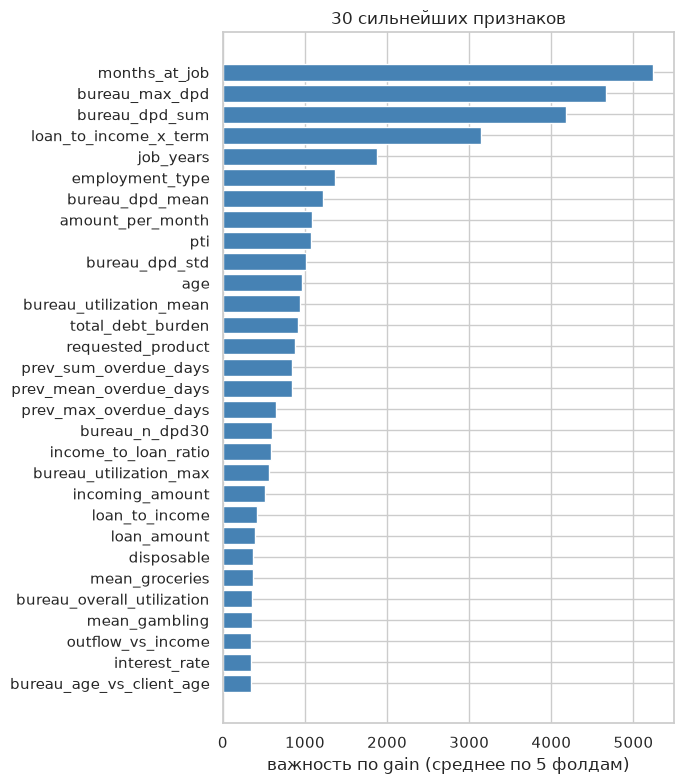

In [23]:
fig, ax = plt.subplots(figsize=(7, 8))
top = importance.head(30)[::-1]
ax.barh(top.index, top.to_numpy(), color="steelblue")
ax.set_xlabel("важность по gain (среднее по 5 фолдам)")
ax.set_title("30 сильнейших признаков")
plt.tight_layout()
plt.show()

### Проверка: во что обошлась бы вера в важности

Выше показали, что `marketing_segment` не предсказывает ничего вне фолда. Посмотрим,
какое место он занял бы в списке важностей, если бы мы отбирали признаки по gain
не глядя.

In [24]:
probe_cols = feature_pool + ["marketing_segment"]
X_probe, _, probe_cats = to_matrix(train_fe, test_fe, probe_cols)

probe_gain = np.zeros(len(probe_cols))
for i, (tr_idx, va_idx) in enumerate(
    StratifiedKFold(5, shuffle=True, random_state=7).split(X_probe, y)
):
    m = lgb.LGBMClassifier(
        objective="binary",
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=60,
        subsample=0.7,
        colsample_bytree=0.6,
        reg_lambda=2.0,
        reg_alpha=1.0,
        n_estimators=2000,
        verbosity=-1,
        random_state=i,
    )
    m.fit(
        X_probe.iloc[tr_idx],
        y.iloc[tr_idx],
        eval_set=[(X_probe.iloc[va_idx], y.iloc[va_idx])],
        eval_metric="auc",
        categorical_feature=probe_cats,
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    probe_gain += m.booster_.feature_importance(importance_type="gain")

probe = pd.Series(probe_gain / 5, index=probe_cols).sort_values(ascending=False)
place = probe.index.get_loc("marketing_segment") + 1
print(f"marketing_segment по gain: место {place} из {len(probe_cols)}")
print(probe.head(6).round(0).to_string())

marketing_segment по gain: место 4 из 229
months_at_job            4719.0
bureau_dpd_sum           4154.0
bureau_max_dpd           4034.0
marketing_segment        3583.0
loan_to_income_x_term    3128.0
job_years                2001.0


Признак, у которого out-of-fold AUC равен 0.502, попадает в самую верхушку рейтинга
важностей. Это и есть главный практический вывод раздела: **важность по gain измеряет,
сколько модель на признаке выучила, а не сколько он предсказывает.** Отбирать признаки
только по gain, без проверки вне фолда, - способ занести шум в модель и не заметить этого.

В наших замерах удаление одного `marketing_segment` давало около **+0.008 OOF AUC** -
крупнейший единичный прирост во всей работе.

В верхушке - ровно то, что ожидается от кредитного скоринга, и это хороший знак
осмысленности модели: стаж на работе, просрочки в бюро (`bureau_max_dpd`, `bureau_dpd_sum`,
`bureau_n_dpd30`), долговая нагрузка (`pti`, `total_debt_burden`, `loan_to_income_x_term`),
история просрочек по прошлым займам, тип занятости.

Заметная часть топа - признаки, которых нет в сырых данных: `total_debt_burden`, `pti`,
`prev_overdue_rate_recw`, `salary_cv`, `gamb_vs_income`, `bal_std`, `in_trend_90`.

### **5. Модели и валидация**

### Схема валидации

`RepeatedStratifiedKFold` 5 фолдов × 3 повтора. Повторы здесь не роскошь: на 6488 строках
разброс AUC между разбиениями порядка 0.005, и по одному 5-фолдовому прогону невозможно
отличить реальное улучшение от везения. Усреднение по 15 фолдам снижает этот шум примерно
вдвое. Предсказания на test усредняются по всем 15 моделям - это ещё и бэггинг.

### Выбор моделей

Берём три модели **разной природы**, а не три варианта одного бустинга:

| модель | почему она в ансамбле |
|---|---|
| **CatBoost** | сильнейшая одиночная модель на этих данных. Упорядоченное кодирование категорий работает лучше нативных категорий LightGBM |
| **LightGBM** | мелкие деревья (`max_depth=3`), сильная регуляризация. Другая схема работы с категориями и другой профиль ошибок |
| **LogisticRegression** | принципиально другой класс гипотез. Ранговая корреляция с бустингами всего 0.93 против 0.99 между самими бустингами - именно поэтому она полезна в бленде |

Гиперпараметры бустингов подбирались отдельно и оказались **очень пологими**: у CatBoost
depth 4/5/6 дают 0.8401 / 0.8400 / 0.8397, изменения `l2_leaf_reg`, `rsm`, `grow_policy`
уводят вниз. Поэтому взяты консервативные значения без тонкой подгонки - выигрыш в этой
задаче даёт чистка признаков, а не тюнинг.

Ранняя остановка идёт по валидационному фолду, что немного завышает OOF-оценку; это
одинаково влияет на все три модели и не меняет их сравнение между собой.

In [25]:
LGB_PARAMS = dict(
    objective="binary",
    metric="auc",
    learning_rate=0.02,
    max_depth=3,
    num_leaves=8,  # мелкие деревья: 6488 строк не выдерживают глубоких
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.6,
    reg_lambda=5.0,
    reg_alpha=2.0,
    n_estimators=4000,  # реальное число подберёт ранняя остановка
    verbosity=-1,
)

CB_PARAMS = dict(
    iterations=4000,
    learning_rate=0.02,
    depth=5,
    l2_leaf_reg=3,
    eval_metric="AUC",
    early_stopping_rounds=150,
    verbose=False,
    allow_writing_files=False,
)

CAT_FEATURES = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_fe[c])]
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]
print("категориальные в финальном наборе:", CAT_FEATURES)


def build_logreg(seed):
    """Линейная модель требует явного препроцессинга: импутация, шкалирование, one-hot.

    Масштаб признаков намеренно оставлен исходным (без квантильного преобразования):
    проверка показала, что переход к рангам роняет качество линейной модели с 0.833 до
    0.812 - связь с таргетом близка к линейной именно в исходных величинах.
    """
    pre = ColumnTransformer(
        [
            (
                "num",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler()),
                    ]
                ),
                NUM_FEATURES,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                CAT_FEATURES,
            ),
        ]
    )
    return Pipeline(
        [
            ("pre", pre),
            ("model", LogisticRegression(C=0.1, max_iter=2000, random_state=seed)),
        ]
    )

категориальные в финальном наборе: ['employment_type', 'requested_product']


In [26]:
# Три представления одних и тех же признаков - под требования каждой библиотеки.
X_lgb, X_lgb_test, _ = to_matrix(train_fe, test_fe, FEATURES)  # pandas category
X_plain, X_plain_test = (
    train_fe[FEATURES].copy(),
    test_fe[FEATURES].copy(),
)  # для sklearn
X_cb, X_cb_test = (
    X_plain.copy(),
    X_plain_test.copy(),
)  # CatBoost не любит NaN в категориях
for c in CAT_FEATURES:
    X_cb[c] = X_cb[c].fillna("missing").astype(str)
    X_cb_test[c] = X_cb_test[c].fillna("missing").astype(str)
cb_cat_idx = [X_cb.columns.get_loc(c) for c in CAT_FEATURES]

MODELS = ["catboost", "lightgbm", "logreg"]
oof = {m: np.zeros(len(train_fe)) for m in MODELS}
test_pred = {m: np.zeros(len(test_fe)) for m in MODELS}
fold_count = np.zeros(len(train_fe))

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE
)
n_models = N_SPLITS * N_REPEATS

for i, (tr_idx, va_idx) in enumerate(cv.split(X_lgb, y)):
    seed = RANDOM_STATE + i

    cb = CatBoostClassifier(**CB_PARAMS, cat_features=cb_cat_idx, random_seed=seed)
    cb.fit(
        X_cb.iloc[tr_idx], y.iloc[tr_idx], eval_set=(X_cb.iloc[va_idx], y.iloc[va_idx])
    )
    oof["catboost"][va_idx] += cb.predict_proba(X_cb.iloc[va_idx])[:, 1]
    test_pred["catboost"] += cb.predict_proba(X_cb_test)[:, 1] / n_models

    gbm = lgb.LGBMClassifier(**LGB_PARAMS, random_state=seed)
    gbm.fit(
        X_lgb.iloc[tr_idx],
        y.iloc[tr_idx],
        eval_set=[(X_lgb.iloc[va_idx], y.iloc[va_idx])],
        eval_metric="auc",
        categorical_feature=CAT_FEATURES,
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    oof["lightgbm"][va_idx] += gbm.predict_proba(X_lgb.iloc[va_idx])[:, 1]
    test_pred["lightgbm"] += gbm.predict_proba(X_lgb_test)[:, 1] / n_models

    lr = build_logreg(seed)
    lr.fit(X_plain.iloc[tr_idx], y.iloc[tr_idx])
    oof["logreg"][va_idx] += lr.predict_proba(X_plain.iloc[va_idx])[:, 1]
    test_pred["logreg"] += lr.predict_proba(X_plain_test)[:, 1] / n_models

    fold_count[va_idx] += 1
    if (i + 1) % N_SPLITS == 0:
        print(f"повтор {(i + 1) // N_SPLITS} из {N_REPEATS} готов")

for m in MODELS:
    oof[m] /= fold_count  # каждая строка попадает в валидацию N_REPEATS раз
    print(f"OOF ROC-AUC {m:10s} {roc_auc_score(y, oof[m]):.5f}")

повтор 1 из 3 готов
повтор 2 из 3 готов
повтор 3 из 3 готов
OOF ROC-AUC catboost   0.83968
OOF ROC-AUC lightgbm   0.83848
OOF ROC-AUC logreg     0.83291


### **6. Блендинг**

Два решения, которые стоит объяснить.

**Смешиваем ранги, а не вероятности.** Метрика зависит только от порядка, а три модели
калиброваны по-разному: у логистической регрессии предсказания сжаты к центру, у бустингов
растянуты к краям. При смешивании вероятностей бустинги молча получают больший вес.
Переход к рангам убирает этот эффект.

**Веса равные, не подобранные.** Перебор весов по OOF даёт 0.84201 против 0.84186 у равных -
выигрыш 0.0002 при том, что стандартная ошибка AUC на тесте из 2520 строк около 0.009.
Подбирать веса под OOF в такой ситуации - это подгонка под шум конкретного разбиения.
Равные веса при трёх примерно равносильных и слабо скоррелированных моделях - устойчивый выбор.

Проверим ранговые корреляции, чтобы убедиться, что модели действительно разные.

In [27]:
ranks_oof = {m: rankdata(oof[m]) / len(y) for m in MODELS}
print("Ранговая корреляция OOF-предсказаний:")
print(pd.DataFrame(ranks_oof).corr(method="spearman").round(3).to_string())

blend_oof = sum(ranks_oof.values()) / len(MODELS)
scores = {m: roc_auc_score(y, oof[m]) for m in MODELS}
scores["БЛЕНД (rank-mean)"] = roc_auc_score(y, blend_oof)
pd.Series(scores).round(5).to_frame("OOF ROC-AUC")

Ранговая корреляция OOF-предсказаний:
          catboost  lightgbm  logreg
catboost     1.000     0.987   0.938
lightgbm     0.987     1.000   0.932
logreg       0.938     0.932   1.000


,OOF ROC-AUC
catboost,0.83968
lightgbm,0.83848
logreg,0.83291
БЛЕНД (rank-mean),0.84139


CatBoost и LightGBM скоррелированы на 0.99, логистическая регрессия - на 0.93. Именно она
и даёт бленду прирост: две почти одинаковые модели смешивать бессмысленно.

Бленд обходит лучшую одиночную модель примерно на 0.0015.

## **7. Формирование `submisson.csv`**

Предсказания на test - среднее рангов трёх моделей, каждая из которых сама усреднена
по 15 фолдам. Ранги нормированы на отрезок (0, 1]; для ROC-AUC важен только порядок,
поэтому монотонное преобразование итог не меняет.

Порядок строк выравниваем по `sample_submission.csv`.

In [30]:
ranks_test = {m: rankdata(test_pred[m]) / len(test_fe) for m in MODELS}
blend_test = sum(ranks_test.values()) / len(MODELS)

submission = pd.DataFrame(
    {"application_id": test_fe["application_id"], "target": blend_test}
)

sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert set(submission["application_id"]) == set(sample["application_id"])
assert submission["application_id"].is_unique
assert submission["target"].notna().all()
submission = (
    submission.set_index("application_id").loc[sample["application_id"]].reset_index()
)

submission.to_csv(ROOT / "submission.csv", index=False)
print(f"submisson.csv сохранён: {submission.shape[0]} строк")
print(f"OOF ROC-AUC блендa: {roc_auc_score(y, blend_oof):.5f}")
submission.head()

submisson.csv сохранён: 2520 строк
OOF ROC-AUC блендa: 0.84139


,application_id,target
0,102531,0.862302
1,107213,0.838095
2,100238,0.415741
3,104918,0.388360
4,106480,0.691270


### **8. Выводы**

**Что дало результат**

1. **Убрали три признака-утечки.** `post_loan_collection_score` (univariate AUC 0.91) и
   `days_until_first_overdue` (0.95) описывают события после выдачи займа и на 100%
   пропущены в test. Модель `simple_baseline.ipynb` построена на них и на тесте вырождается.

2. **Нашли шум, замаскированный под сильный признак.** `marketing_segment` попадает
   в верхушку рейтинга важностей по gain, но сравнение in-fold (0.589) и out-of-fold (0.502)
   target encoding показывает, что это чистое запоминание 150 мелких категорий. Его удаление - крупнейший единичный
   прирост в работе, около +0.008 AUC. Тот же приём выявил шум в `channel` и `education`.

3. **Проверили числовые признаки измерением, а не глазами.** `region_coefficient`
   оказался константой, а `region_coefficient_extended`, `siberia_northern_score` и
   `dependents` дают univariate AUC на уровне 0.500 при том, что на KDE-графиках их
   распределения по классам выглядят различающимися.

4. **Использовали время транзакций.** Оконные агрегаты за 30 и 90 дней, тренды, recency,
   регулярность зарплаты, прокси остатка на счёте. Производные от них признаки
   (`total_debt_burden`, `gamb_vs_income`, `salary_cv`, `bal_std`, `in_trend_90`) заняли
   заметную часть финального топ-55.

5. **Отобрали признаки по gain.** На полном пуле из 237 признаков модель даёт 0.8338,
   на 55 отобранных - 0.8385. Больше признаков на 6488 строках означает хуже.

6. **Смешали три модели разной природы по рангам с равными весами.**

**Что проверили и сознательно не стали делать**

- **Не подбирали веса блендa.** Перебор даёт +0.0002 к равным весам при стандартной ошибке
  метрики около 0.009 - это подгонка под шум.
- **Не тюнили бустинги глубоко.** Сетка по CatBoost укладывается в диапазон 0.8379–0.8401,
  то есть в пределы шума; выигрыш даёт работа с признаками.
- **Не добавляли явные признаки-взаимодействия.** Разности вида
  `bureau_dpd_std - job_years` дают univariate AUC 0.748 против 0.679 у сильнейшего
  родителя, но при добавлении в модель качество падает (0.8354 против 0.8372): деревья
  этот сигнал уже извлекают через сплиты, а коллинеарные колонки размывают важности.
- **Не расширяли ансамбль дальше.** ExtraTrees (0.829), RandomForest (0.824),
  HistGradientBoosting (0.834) и MLP (0.820) слабее и не улучшают бленд.
- **Не использовали псевдо-лейблинг и коррекцию под сдвиг.** Adversarial validation даёт
  AUC около 0.5 - сдвига между train и test нет.

**Ограничение оценки.** Тестовая выборка - 2520 строк, стандартная ошибка ROC-AUC на ней
порядка 0.009. Разница в 0.002–0.003 между вариантами модели на таком объёме неразличима,
и это причина, по которой мы всюду предпочитали устойчивые решения точечно оптимальным.